In [1]:
!pip install imbalanced-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.5/13.5 MB 101.2 MB/s eta 0:00:0000:0100:01
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.2.2
    Uninstalling scikit-learn-1.2.2:
      Successfully uninstalled scikit-learn-1.2.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
category-encoders 2.7.0 requires scikit-learn<1.6.0,>=1.0.0, but you have scikit-learn 1.6.1 which is incompatible.
cesium 0.12.4 requires numpy<3.0,>=2.0, but you have numpy 1.26.4 which is incompatible.


In [2]:
!pip install pytorch-tabnet


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 99.2 MB/s eta 0:00:00:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 67.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 40.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 8.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 31.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 8.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 8.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 88.6 MB/s eta 0:00:00:00:0100:01
  Attempting uninstall: nvi

In [3]:
! pip install sklearn pytorch-tabnet catboost lightgbm

  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (setup.py) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> See above for output.

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.


In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Combining the dataset

In [5]:
import pandas as pd
import os

# Define input directory
input_dir = '/kaggle/input/cicddos2019/'

# List all parquet files
files = [os.path.join(input_dir, f) for f in os.listdir(input_dir) if f.endswith('.parquet')]

# Function to check if all files have the same columns
def check_columns(files):
    print("Checking if all files have the same columns...")
    first_file = pd.read_parquet(files[0])
    reference_columns = set(first_file.columns)
    
    for file in files[1:]:
        df = pd.read_parquet(file)
        current_columns = set(df.columns)
        if current_columns != reference_columns:
            print(f"File {file} has different columns!")
            print(f"Reference columns: {reference_columns}")
            print(f"Current columns: {current_columns}")
            return False
    print("All files have the same columns!")
    return True

# Function to combine datasets
def combine_datasets():
    # Check columns consistency
    if not check_columns(files):
        print("Cannot combine datasets due to inconsistent columns.")
        return
    
    # Combine all datasets
    print("Combining all datasets...")
    all_dfs = [pd.read_parquet(f) for f in files]
    combined_data = pd.concat(all_dfs, ignore_index=True)
    combined_data.to_csv('/kaggle/working/Combined Dataset.csv', index=False)
    print(f"Combined dataset saved as Combined Dataset.csv with {len(combined_data)} rows")

# Execute the combination
if __name__ == "__main__":
    combine_datasets()

Checking if all files have the same columns...
All files have the same columns!
Combining all datasets...
Combined dataset saved as Combined Dataset.csv with 431371 rows


# Loading combined dataset

In [6]:
df = pd.read_csv("/kaggle/working/Combined Dataset.csv")

# EDA, data cleaning and preprocessing

In [7]:
df.head()

,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,6,105,2,2,12.0,12.0,6.0,6.0,6.0,0.0,...,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Syn
1,6,1,2,0,12.0,0.0,6.0,6.0,6.0,0.0,...,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Syn
2,6,55295858,8,0,48.0,0.0,6.0,6.0,6.0,0.0,...,20,1.0,0.0,1.0,1.0,18431952.0,4641289.0,22000140.0,13184826.0,Syn
3,6,49,2,0,12.0,0.0,6.0,6.0,6.0,0.0,...,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Syn
4,6,109,2,2,12.0,12.0,6.0,6.0,6.0,0.0,...,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Syn


In [8]:
df.shape

(431371, 78)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 431371 entries, 0 to 431370
Data columns (total 78 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Protocol                  431371 non-null  int64  
 1   Flow Duration             431371 non-null  int64  
 2   Total Fwd Packets         431371 non-null  int64  
 3   Total Backward Packets    431371 non-null  int64  
 4   Fwd Packets Length Total  431371 non-null  float64
 5   Bwd Packets Length Total  431371 non-null  float64
 6   Fwd Packet Length Max     431371 non-null  float64
 7   Fwd Packet Length Min     431371 non-null  float64
 8   Fwd Packet Length Mean    431371 non-null  float64
 9   Fwd Packet Length Std     431371 non-null  float64
 10  Bwd Packet Length Max     431371 non-null  float64
 11  Bwd Packet Length Min     431371 non-null  float64
 12  Bwd Packet Length Mean    431371 non-null  float64
 13  Bwd Packet Length Std     431371 non-null  f

In [10]:
df.describe()

,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Fwd Act Data Packets,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
count,431371.000000,4.313710e+05,431371.000000,431371.000000,4.313710e+05,4.313710e+05,431371.000000,431371.000000,431371.000000,431371.000000,...,431371.000000,4.313710e+05,4.313710e+05,4.313710e+05,4.313710e+05,4.313710e+05,4.313710e+05,4.313710e+05,4.313710e+05,4.313710e+05
mean,13.948694,8.404856e+06,24.139117,2.472021,9.416956e+03,1.632896e+03,357.483674,294.721646,324.915327,20.208259,...,21.893124,-2.315406e+07,3.370905e+04,2.563697e+04,6.757181e+04,1.868363e+04,2.449924e+06,4.983262e+05,2.971142e+06,1.993859e+06
std,4.966712,2.126596e+07,195.888896,56.370208,3.445253e+04,1.064056e+05,320.025929,273.298705,268.577313,70.946085,...,54.559772,1.551755e+08,3.223119e+05,2.226543e+05,5.183739e+05,2.832011e+05,7.914010e+06,2.005164e+06,9.045327e+06,7.245561e+06
min,0.000000,1.000000e+00,1.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,...,0.000000,-1.408238e+09,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.000000,7.870000e+02,4.000000,0.000000,7.800000e+01,0.000000e+00,37.000000,6.000000,32.000000,0.000000,...,1.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,17.000000,4.480400e+04,4.000000,0.000000,2.064000e+03,0.000000e+00,440.000000,330.000000,428.000000,0.000000,...,3.000000,2.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,17.000000,3.002508e+06,16.000000,2.000000,5.160000e+03,0.000000e+00,516.000000,516.000000,516.000000,0.000000,...,13.000000,2.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,17.000000,1.199987e+08,86666.000000,31700.000000,1.526642e+07,5.842950e+07,32120.000000,2131.000000,3015.290500,2221.556200,...,18766.000000,6.724045e+07,4.050800e+07,2.135244e+07,4.553668e+07,4.050800e+07,1.192194e+08,6.961402e+07,1.192194e+08,1.192194e+08


In [11]:
# Check the exact column names
df.columns

Index(['Protocol', 'Flow Duration', 'Total Fwd Packets',
       'Total Backward Packets', 'Fwd Packets Length Total',
       'Bwd Packets Length Total', 'Fwd Packet Length Max',
       'Fwd Packet Length Min', 'Fwd Packet Length Mean',
       'Fwd Packet Length Std', 'Bwd Packet Length Max',
       'Bwd Packet Length Min', 'Bwd Packet Length Mean',
       'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s',
       'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min',
       'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max',
       'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std',
       'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags',
       'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length',
       'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s',
       'Packet Length Min', 'Packet Length Max', 'Packet Length Mean',
       'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count',
       'SYN Flag Count', 'RST Fla

In [12]:
df.dtypes

Protocol                      int64
Flow Duration                 int64
Total Fwd Packets             int64
Total Backward Packets        int64
Fwd Packets Length Total    float64
                             ...   
Idle Mean                   float64
Idle Std                    float64
Idle Max                    float64
Idle Min                    float64
Label                        object
Length: 78, dtype: object

In [13]:
df['Label'].value_counts()

Label
DrDoS_NTP        121368
TFTP              98917
Benign            97831
Syn               49373
UDP               18090
DrDoS_UDP         10420
UDP-lag            8872
MSSQL              8523
DrDoS_MSSQL        6212
DrDoS_DNS          3669
DrDoS_SNMP         2717
LDAP               1906
DrDoS_LDAP         1440
Portmap             685
NetBIOS             644
DrDoS_NetBIOS       598
UDPLag               55
WebDDoS              51
Name: count, dtype: int64

In [14]:
# List of labels to drop
labels_to_drop = ['Portmap', 'NetBIOS', 'DrDoS_NetBIOS', 'UDPLag', 'WebDDoS']

# Drop rows where 'Label' is in labels_to_drop
df = df[~df['Label'].isin(labels_to_drop)]

In [15]:
# Create a new column 'Binary_Label' with 'Benign' or 'Attack'
df['Binary_Label'] = df['Label'].apply(lambda x: 'Benign' if x == 'Benign' else 'Attack')

In [16]:
# Remove leading/trailing whitespaces from column names
df.columns = df.columns.str.strip()

In [17]:
df.head()

,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Binary_Label
0,6,105,2,2,12.0,12.0,6.0,6.0,6.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Syn,Attack
1,6,1,2,0,12.0,0.0,6.0,6.0,6.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Syn,Attack
2,6,55295858,8,0,48.0,0.0,6.0,6.0,6.0,0.0,...,1.0,0.0,1.0,1.0,18431952.0,4641289.0,22000140.0,13184826.0,Syn,Attack
3,6,49,2,0,12.0,0.0,6.0,6.0,6.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Syn,Attack
4,6,109,2,2,12.0,12.0,6.0,6.0,6.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Syn,Attack


In [18]:
# Drop the 'Label' column
df = df.drop('Label', axis=1)

In [19]:
# Check for duplicates
duplicates = df.duplicated().sum()
print("Number of duplicate rows:", duplicates)

# Remove duplicates from the training dataset
df = df.drop_duplicates()
print("Number of duplicate rows in after removal:", df.duplicated().sum())

Number of duplicate rows: 11514
Number of duplicate rows in after removal: 0


In [20]:
# Check null values
nulls = df.isnull().sum().sort_values(ascending=False)
print(nulls[nulls > 0])

# check for some null or missing values
df.isna().sum().to_numpy()

Series([], dtype: int64)


array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

# Data Visulaization

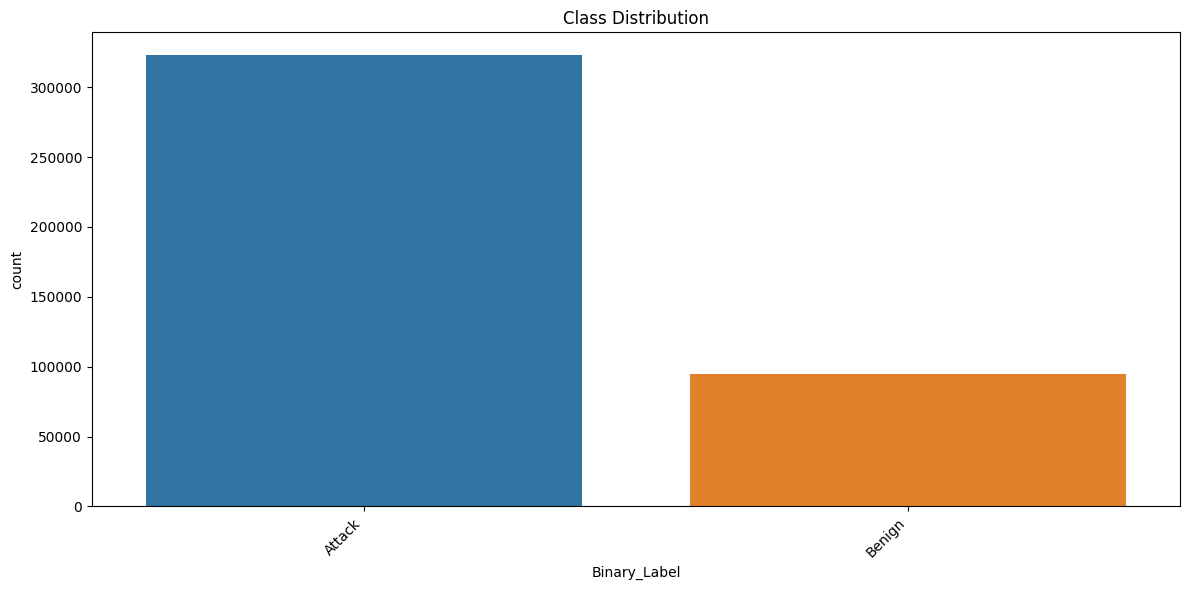

Class counts:
Binary_Label
Attack    323142
Benign     94682
Name: count, dtype: int64

Imbalance Ratio (minority/majority): 0.2930


In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a wider figure
plt.figure(figsize=(12, 6))  # Increase width (12) to make the plot wider

# Plot label distribution
sns.countplot(data=df, x='Binary_Label')
plt.title('Class Distribution')
plt.xticks(rotation=45, ha='right')  # Rotate x-axis labels for better readability
plt.tight_layout()  # Adjust layout to prevent label cutoff
plt.show()

# Count the occurrences of each class
class_counts = df['Binary_Label'].value_counts()

# Calculate imbalance ratio (minority / majority)
imbalance_ratio = class_counts.min() / class_counts.max()

print("Class counts:")
print(class_counts)
print(f"\nImbalance Ratio (minority/majority): {imbalance_ratio:.4f}")


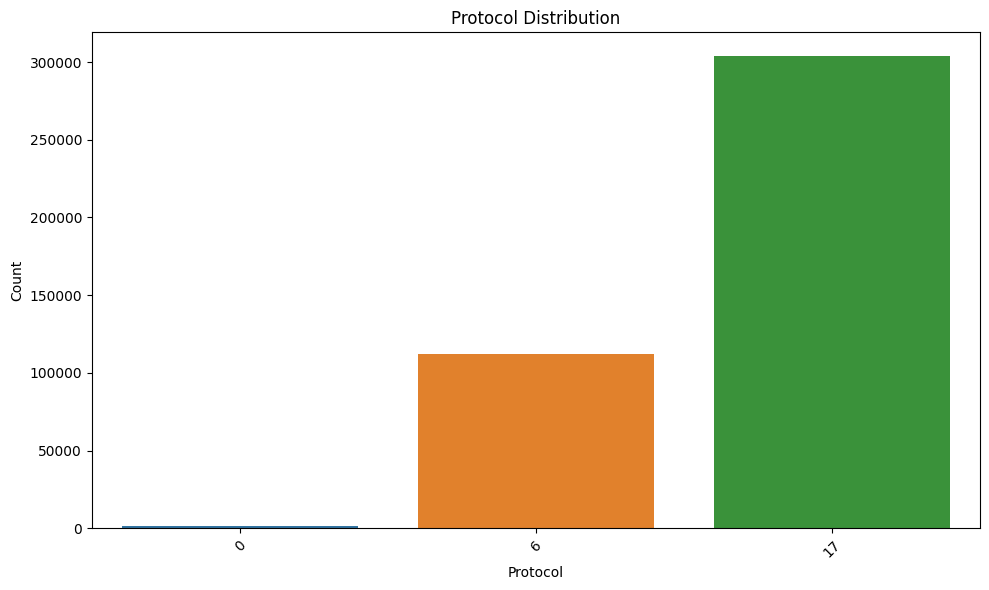

Protocol Value Counts:
 Protocol
17    303927
6     112281
0       1616
Name: count, dtype: int64


In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

# Protocol Distribution
# Insight: Shows which protocols (e.g., TCP=6, UDP=17) are most common in the dataset.
# Useful for NIDS: DDoS attacks often exploit specific protocols like UDP for amplification.
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Protocol')
plt.title('Protocol Distribution')
plt.xlabel('Protocol')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Print value counts for deeper insight
print("Protocol Value Counts:\n", df['Protocol'].value_counts())

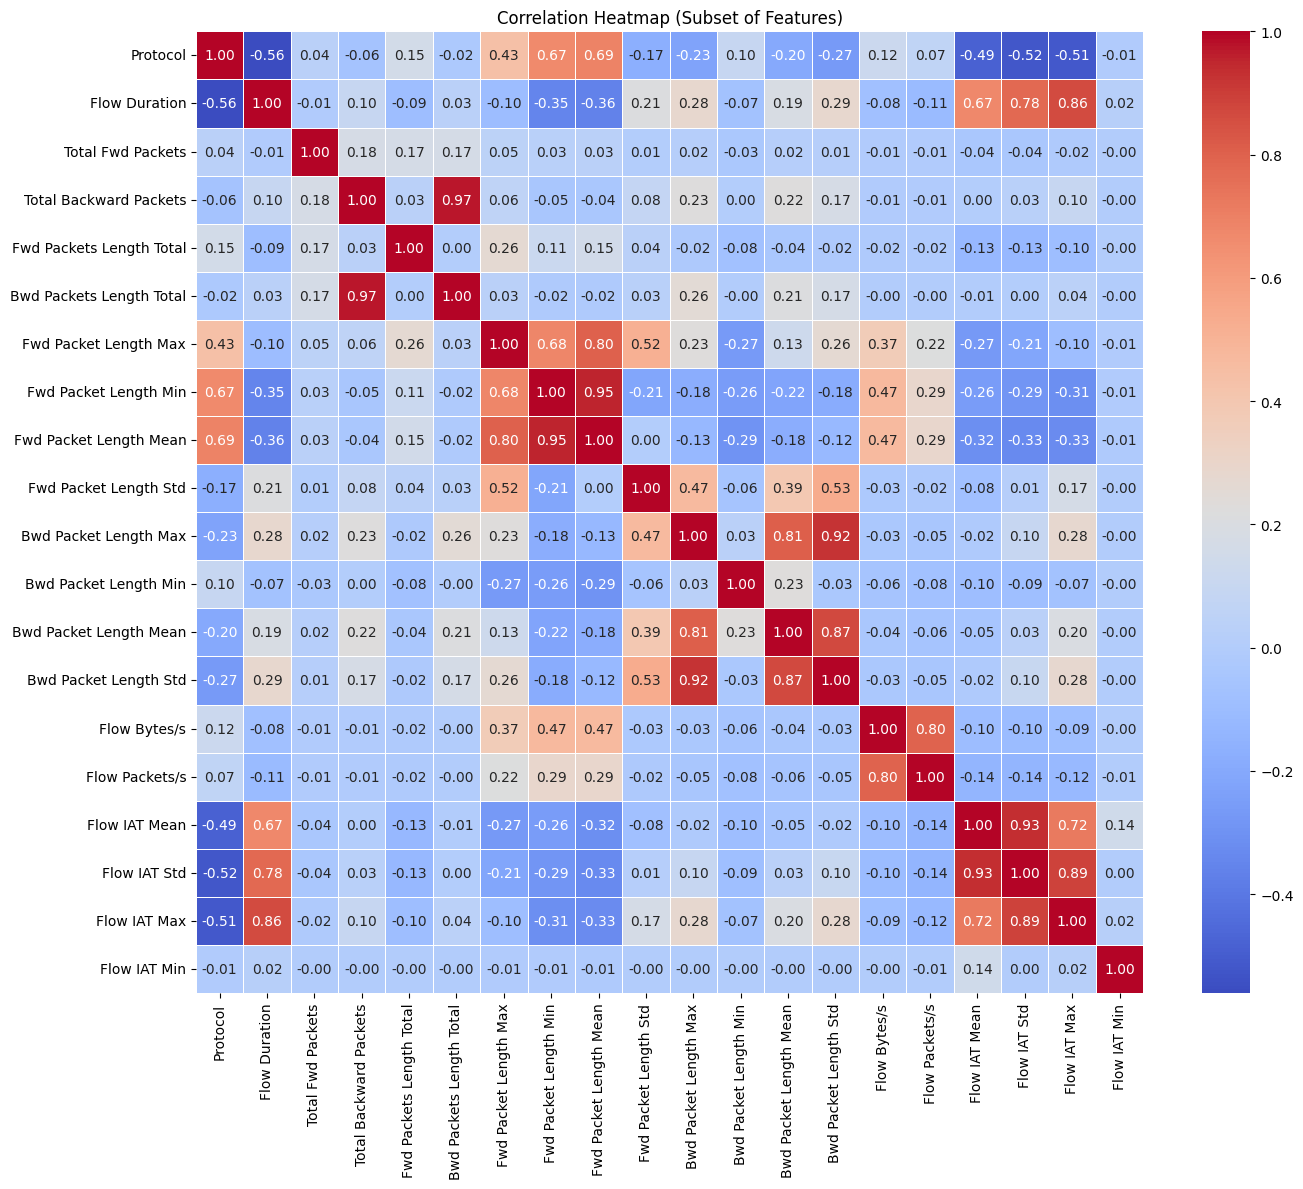

Top Highly Correlated Feature Pairs:
 Flow Duration          Fwd IAT Total            0.998833
Fwd IAT Total          Flow Duration            0.998833
Fwd Packet Length Min  Packet Length Min        0.996454
Packet Length Min      Fwd Packet Length Min    0.996454
Flow IAT Min           Fwd IAT Min              0.996232
Fwd IAT Min            Flow IAT Min             0.996232
Fwd Packets/s          Flow Packets/s           0.996193
Flow Packets/s         Fwd Packets/s            0.996193
Flow IAT Max           Fwd IAT Max              0.995868
Fwd IAT Max            Flow IAT Max             0.995868
dtype: float64


/usr/local/lib/python3.11/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in less
  return op(a, b)


In [23]:
# Correlation Heatmap (Select a subset of features to avoid clutter)
# Insight: Identifies highly correlated features, which can indicate redundancy.
# For NIDS: Helps in feature selection to reduce model complexity without losing information.
numeric_df = df.select_dtypes(include=[np.number])  # Only numeric columns
corr_matrix = numeric_df.corr()

# Plot heatmap for correlations (focus on a subset for clarity, e.g., top 20 features)
plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix.iloc[:20, :20], annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap (Subset of Features)')
plt.tight_layout()
plt.show()

# To find highly correlated pairs (>0.9 or <-0.9)
high_corr = corr_matrix.abs().unstack().sort_values(ascending=False)
high_corr = high_corr[high_corr < 1].head(10)  # Top 10 pairs excluding self-correlations
print("Top Highly Correlated Feature Pairs:\n", high_corr)

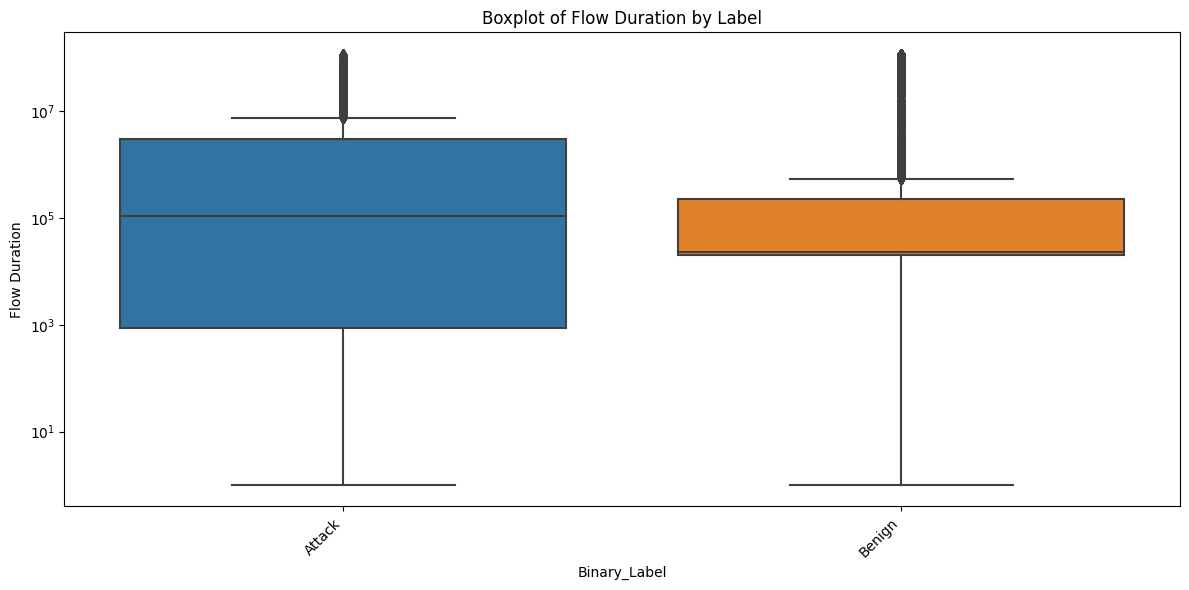

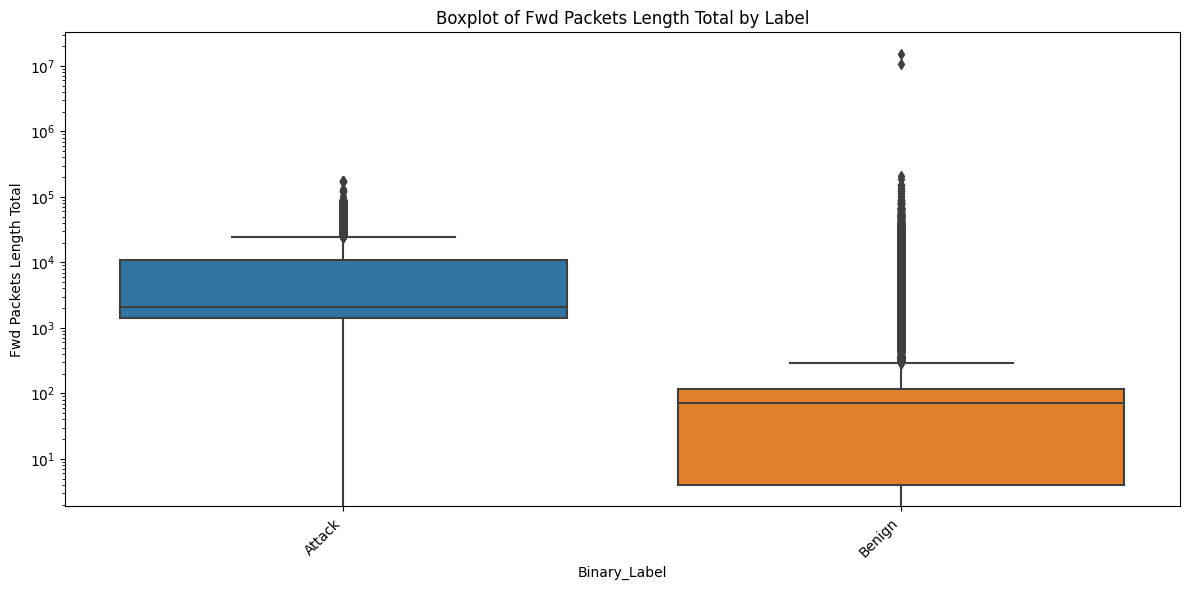

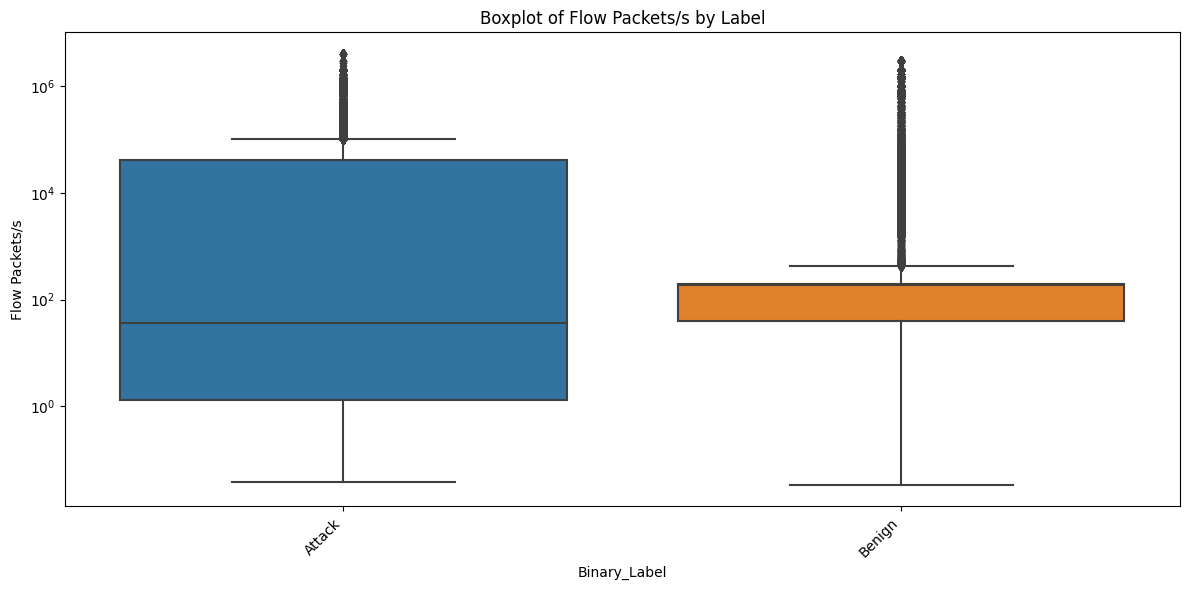

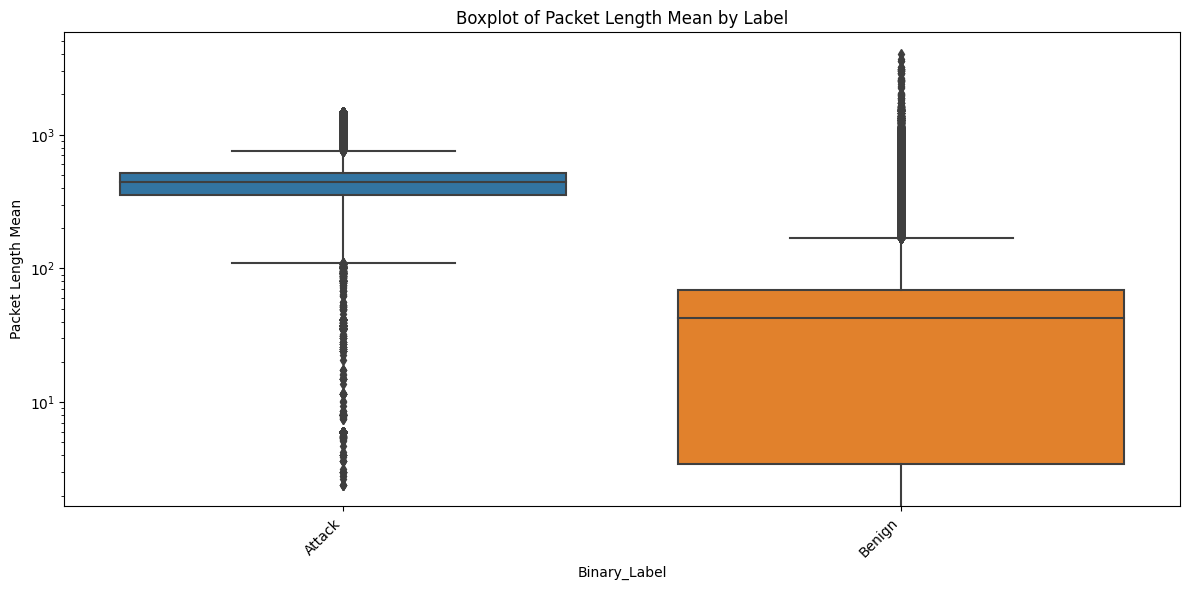

Median Values by Binary_Label:
               Flow Duration  Fwd Packets Length Total  Flow Packets/s  \
Binary_Label                                                            
Attack             108518.0                    2064.0       36.965844   
Benign              22963.0                      72.0      188.199868   

              Packet Length Mean  
Binary_Label                      
Attack                     440.0  
Benign                      42.2  


In [24]:
# Boxplot for Key Features vs Label
# Insight: Compares feature distributions across classes to spot differences.
# Useful for NIDS: Features like 'Flow Duration' or 'Packet Length' can distinguish benign traffic from attacks.
key_features = ['Flow Duration', 'Fwd Packets Length Total', 'Flow Packets/s', 'Packet Length Mean']

for feature in key_features:
    plt.figure(figsize=(12, 6))
    sns.boxplot(data=df, x='Binary_Label', y=feature)
    plt.title(f'Boxplot of {feature} by Label')
    plt.xticks(rotation=45, ha='right')
    plt.yscale('log')  # Log scale for better visibility if values vary widely
    plt.tight_layout()
    plt.show()

# Compute medians for insight
medians = df.groupby('Binary_Label')[key_features].median()
print("Median Values by Binary_Label:\n", medians)

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

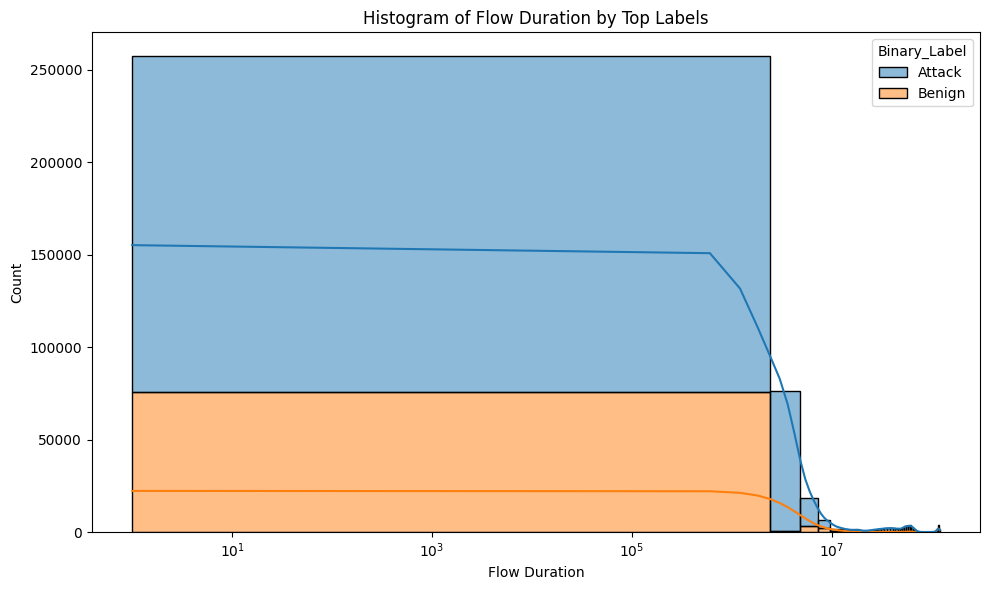

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

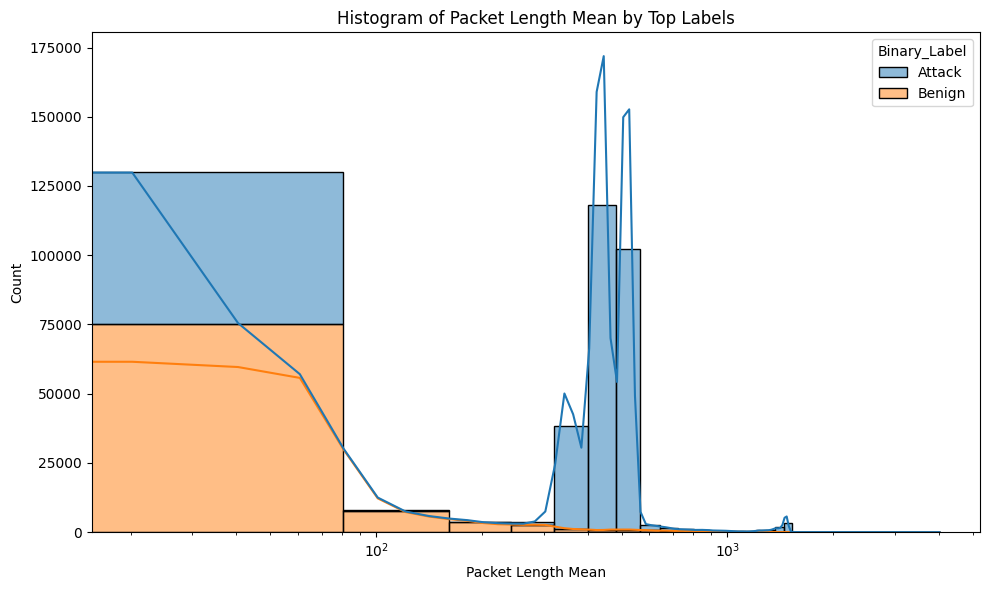

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

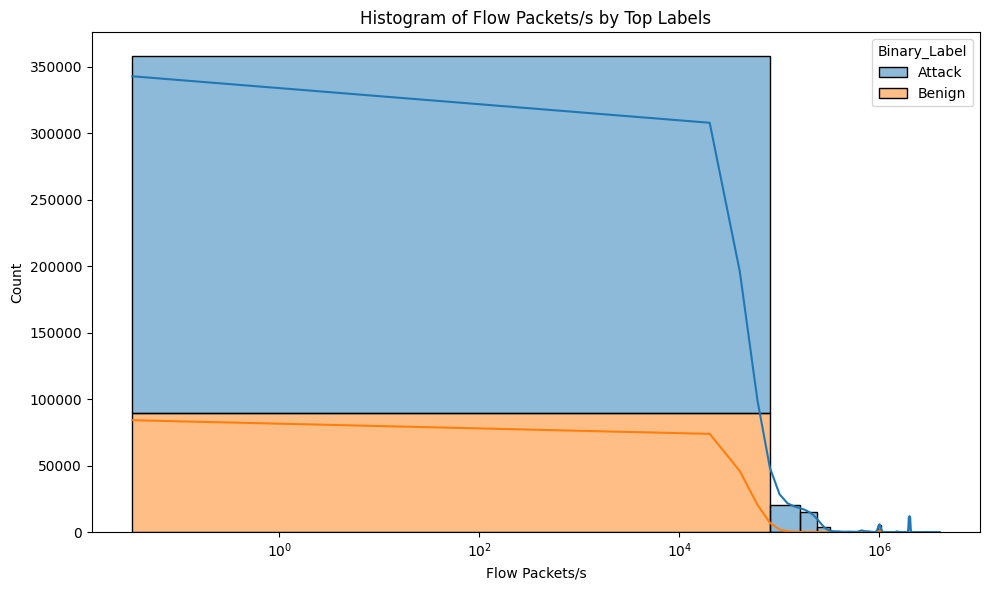

Skewness of Selected Features:
 Flow Duration         3.212017
Packet Length Mean    0.954888
Flow Packets/s        4.709253
dtype: float64


In [25]:
# Histogram for Selected Features (Overall and by Major Classes)
# Insight: Reveals distribution shapes (e.g., skewed, normal) and potential anomalies.
# For NIDS: Skewed features might need transformation (e.g., log) for better model performance.
selected_features = ['Flow Duration', 'Packet Length Mean', 'Flow Packets/s']

# Filter to major classes for clarity (to avoid overcrowding)
major_labels = df['Binary_Label'].value_counts().index[:5]  # Top 5 classes
df_major = df[df['Binary_Label'].isin(major_labels)]

for feature in selected_features:
    plt.figure(figsize=(10, 6))
    sns.histplot(data=df_major, x=feature, hue='Binary_Label', multiple='stack', bins=50, kde=True)
    plt.title(f'Histogram of {feature} by Top Labels')
    plt.xscale('log')  # Log scale if distributions are skewed
    plt.tight_layout()
    plt.show()

# Print skewness for insight
skewness = df[selected_features].skew()
print("Skewness of Selected Features:\n", skewness)

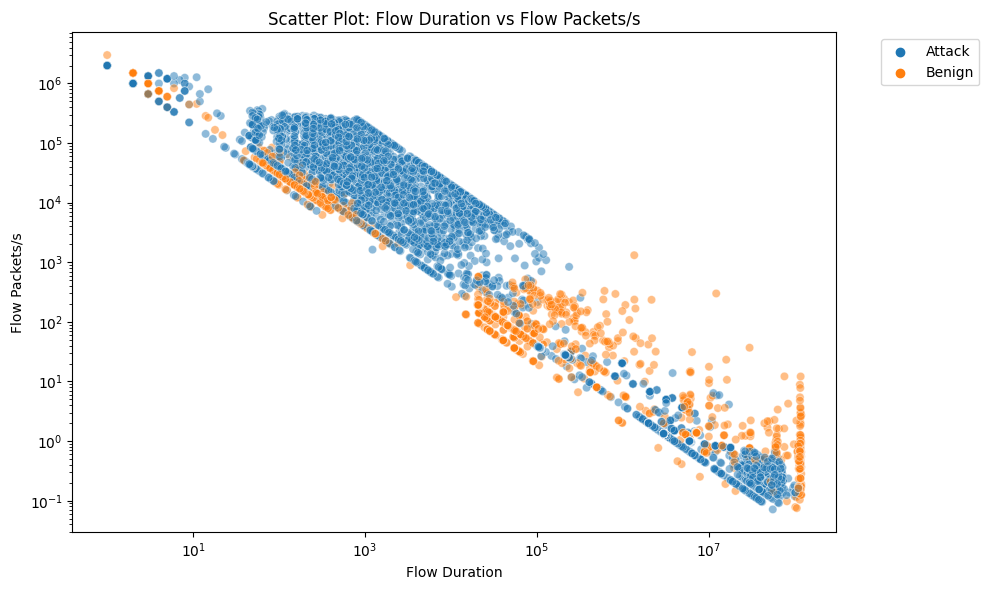

Correlation between Flow Duration and Flow Packets/s: -0.11


In [26]:
# Scatter Plot for Pair of Features (Sampled for Performance)
# Insight: Visualizes relationships between two features, colored by label.
# Useful for NIDS: Helps identify clusters of benign vs. attack traffic.
sample_df = df.sample(n=10000, random_state=42)  # Sample 10k rows to speed up

plt.figure(figsize=(10, 6))
sns.scatterplot(data=sample_df, x='Flow Duration', y='Flow Packets/s', hue='Binary_Label', alpha=0.5)
plt.title('Scatter Plot: Flow Duration vs Flow Packets/s')
plt.xscale('log')
plt.yscale('log')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Compute correlation between these two
corr_value = df['Flow Duration'].corr(df['Flow Packets/s'])
print(f"Correlation between Flow Duration and Flow Packets/s: {corr_value:.2f}")

# Balancing the dataset


Class distribution after balancing:
Binary_Label
Attack    323142
Benign    323142
Name: count, dtype: int64


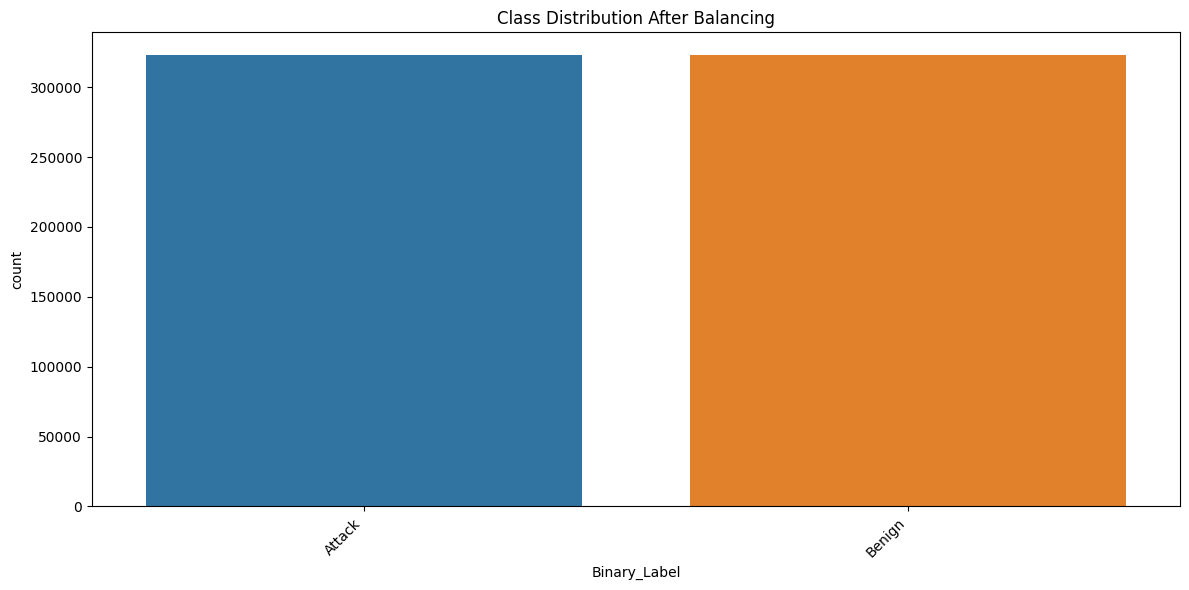

In [27]:
import pandas as pd
import numpy as np
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
import matplotlib.pyplot as plt

# Encode the 'Label' column (SMOTE requires numerical labels)
label_encoder = LabelEncoder()
df['Label_encoded'] = label_encoder.fit_transform(df['Binary_Label'])

# Separate features (X) and target (y)
X = df.drop(['Binary_Label', 'Label_encoded'], axis=1)
y = df['Label_encoded']

# Apply SMOTE to balance the dataset
smote = SMOTE(random_state=42)
X_balanced, y_balanced = smote.fit_resample(X, y)

# Convert back to DataFrame
X_balanced = pd.DataFrame(X_balanced, columns=X.columns)
y_balanced = pd.Series(y_balanced, name='Label_encoded')

# Decode the labels back to original class names
y_balanced_decoded = label_encoder.inverse_transform(y_balanced)

# Create a new balanced DataFrame
df_balanced = pd.concat([X_balanced, pd.Series(y_balanced_decoded, name='Binary_Label')], axis=1)

# Verify the class distribution after balancing
print("\nClass distribution after balancing:")
print(df_balanced['Binary_Label'].value_counts())

# Visualize the class distribution after balancing
plt.figure(figsize=(12, 6))
sns.countplot(data=df_balanced, x='Binary_Label')
plt.title('Class Distribution After Balancing')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [28]:
"""
# Define file path (you can change it as needed)
output_path = "/kaggle/working/balanced_dataset.csv"

# Save to CSV
df_balanced.to_csv(output_path, index=False)

print(f"\n Balanced dataset saved successfully to: {output_path}")

"""

'\n# Define file path (you can change it as needed)\noutput_path = "/kaggle/working/balanced_dataset.csv"\n\n# Save to CSV\ndf_balanced.to_csv(output_path, index=False)\n\nprint(f"\n Balanced dataset saved successfully to: {output_path}")\n\n'

# Encoding the categorical feature "Binary_Label"

In [29]:
from sklearn.preprocessing import LabelEncoder

# Encode the 'Label' column
label_encoder = LabelEncoder()
df_balanced['Label_encoded'] = label_encoder.fit_transform(df_balanced['Binary_Label'])

# Separate features (X) and target (y)
X = df_balanced.drop(['Binary_Label', 'Label_encoded'], axis=1)
y = df_balanced['Label_encoded']

# Print the encoded label mapping and a sample of the converted data
print("Label Encoding Mapping:")
for label, encoded in zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)):
    print(f"{label} → {encoded}")

print("\nEncoded Target Values (y):")
print(y.value_counts())

print("\nSample of Converted DataFrame:")
print(df_balanced.head())


Label Encoding Mapping:
Attack → 0
Benign → 1

Encoded Target Values (y):
Label_encoded
0    323142
1    323142
Name: count, dtype: int64

Sample of Converted DataFrame:
   Protocol  Flow Duration  Total Fwd Packets  Total Backward Packets  \
0         6            105                  2                       2   
1         6              1                  2                       0   
2         6       55295858                  8                       0   
3         6             49                  2                       0   
4         6            109                  2                       2   

   Fwd Packets Length Total  Bwd Packets Length Total  Fwd Packet Length Max  \
0                      12.0                      12.0                    6.0   
1                      12.0                       0.0                    6.0   
2                      48.0                       0.0                    6.0   
3                      12.0                       0.0                  

# FEATURE SELECTION USING MUTUAL INFORMATION

STEP 1: MUTUAL INFORMATION FEATURE SELECTION (Before Normalization)

Top 8 Features by Mutual Information:
                     Feature  MI_Score
52           Avg Packet Size  0.628587
40        Packet Length Mean  0.584887
53      Avg Fwd Segment Size  0.582897
8     Fwd Packet Length Mean  0.582504
4   Fwd Packets Length Total  0.575481
38         Packet Length Min  0.573163
7      Fwd Packet Length Min  0.572117
39         Packet Length Max  0.566567


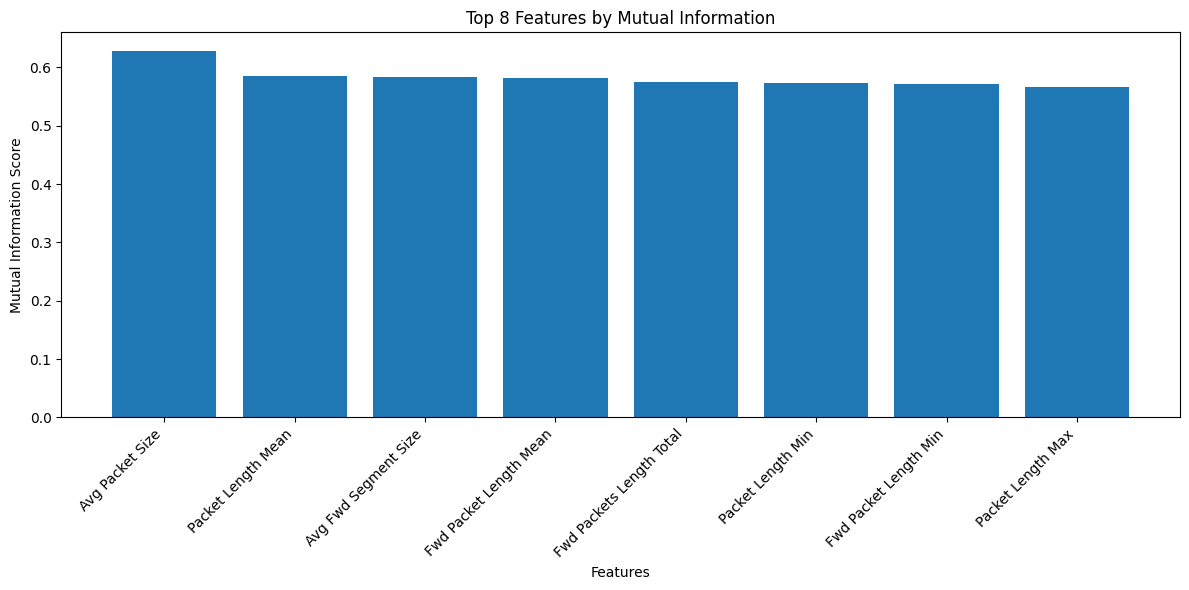


Number of selected features: 8

Selected Features:
  1. Avg Packet Size (MI Score: 0.6286)
  2. Packet Length Mean (MI Score: 0.5849)
  3. Avg Fwd Segment Size (MI Score: 0.5829)
  4. Fwd Packet Length Mean (MI Score: 0.5825)
  5. Fwd Packets Length Total (MI Score: 0.5755)
  6. Packet Length Min (MI Score: 0.5732)
  7. Fwd Packet Length Min (MI Score: 0.5721)
  8. Packet Length Max (MI Score: 0.5666)


In [30]:
from sklearn.feature_selection import mutual_info_classif

# ============================================================================
# STEP 1: FEATURE SELECTION USING MUTUAL INFORMATION
# ============================================================================
print("="*80)
print("STEP 1: MUTUAL INFORMATION FEATURE SELECTION (Before Normalization)")
print("="*80)

# Compute MI scores
mi_scores = mutual_info_classif(X, y, random_state=42, n_neighbors=3)

# Create MI score dataframe
mi_scores_df = pd.DataFrame({
    'Feature': X.columns,
    'MI_Score': mi_scores
}).sort_values(by='MI_Score', ascending=False)

# Show top features
print("\nTop 8 Features by Mutual Information:")
print(mi_scores_df.head(8))

# Plot MI scores
plt.figure(figsize=(12, 6))
plt.bar(range(len(mi_scores_df.head(8))), mi_scores_df.head(8)['MI_Score'])
plt.xticks(range(len(mi_scores_df.head(8))),
           mi_scores_df.head(8)['Feature'], rotation=45, ha='right')
plt.xlabel('Features')
plt.ylabel('Mutual Information Score')
plt.title('Top 8 Features by Mutual Information')
plt.tight_layout()
plt.savefig('mutual_information_scores.png', dpi=300, bbox_inches='tight')
plt.show()

# Select top k features
top_k = 8
selected_features = mi_scores_df.head(top_k)['Feature'].tolist()

print(f"\nNumber of selected features: {len(selected_features)}")
print("\nSelected Features:")
for i, feature in enumerate(selected_features, 1):
    score = mi_scores_df.loc[mi_scores_df['Feature'] == feature, 'MI_Score'].values[0]
    print(f"  {i}. {feature} (MI Score: {score:.4f})")

# Subset the original data using selected features
X_selected = X[selected_features]

# Normalizing the dataset

In [31]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# ============================================================================
# STEP 2: DATA NORMALIZATION (After Feature Selection)
# ============================================================================
print("\n" + "="*80)
print("STEP 2: DATA NORMALIZATION (After Feature Selection)")
print("="*80)

scaler = StandardScaler()
X_normalized = scaler.fit_transform(X_selected)
X_normalized_df = pd.DataFrame(X_normalized, columns=selected_features)

print(f"\nShape after normalization: {X_normalized_df.shape}")


STEP 2: DATA NORMALIZATION (After Feature Selection)

Shape after normalization: (646284, 8)


# Split the dataset into train and test

In [32]:
from sklearn.model_selection import train_test_split

# ============================================================================
# STEP 3: TRAIN/TEST SPLIT
# ============================================================================
print("\n" + "="*80)
print("STEP 3: TRAIN/TEST SPLIT")
print("="*80)

X_train, X_test, y_train, y_test = train_test_split(
    X_normalized_df, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set shape (X_train, y_train):", X_train.shape, y_train.shape)
print("Testing set shape (X_test, y_test):", X_test.shape, y_test.shape)


STEP 3: TRAIN/TEST SPLIT
Training set shape (X_train, y_train): (517027, 8) (517027,)
Testing set shape (X_test, y_test): (129257, 8) (129257,)


# Features Selection, Modeling & Evaluation


STEP 4: MODEL TRAINING

[1/3] Training LightGBM...
✓ LightGBM training completed

[2/3] Training CatBoost...
✓ CatBoost training completed

[3/3] Training Stacking Ensemble...
✓ Stacking Ensemble training completed

STEP 5: MODEL EVALUATION

Evaluating LightGBM...
  Accuracy:  0.9861
  F1-Score:  0.9861
  ROC-AUC:   0.9971

Evaluating CatBoost...
  Accuracy:  0.9859
  F1-Score:  0.9859
  ROC-AUC:   0.9971

Evaluating Stacking...
  Accuracy:  0.9860
  F1-Score:  0.9860
  ROC-AUC:   0.9971

Model Performance Comparison:
   Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
LightGBM  0.986059   0.986318 0.986059  0.986057 0.997130
Stacking  0.986005   0.986261 0.986005  0.986003 0.997118
CatBoost  0.985927   0.986190 0.985927  0.985925 0.997089

Best Performing Model: LightGBM

CONFUSION MATRIX - LightGBM


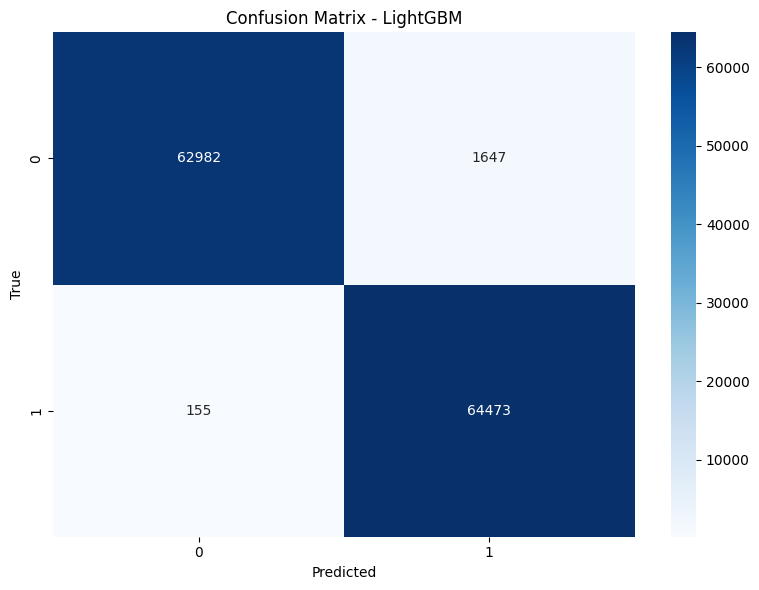


Analysis Complete


In [33]:
# ============================================================================
# IMPORTS
# ============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, roc_auc_score, classification_report, 
                             confusion_matrix, roc_curve, auc)
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
import lightgbm as lgb
from catboost import CatBoostClassifier
import warnings
warnings.filterwarnings('ignore')


# ============================================================================
# STEP 4: MODEL TRAINING
# ============================================================================
print("\n" + "="*80)
print("STEP 4: MODEL TRAINING")
print("="*80)

models = {}
results = {}

# ----------------------------------------------------------------------------
# LightGBM
# ----------------------------------------------------------------------------
print("\n[1/3] Training LightGBM...")
lgb_model = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=10,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbose=-1,
    n_jobs=-1
)
lgb_model.fit(X_train, y_train)
models['LightGBM'] = lgb_model
print("✓ LightGBM training completed")

# ----------------------------------------------------------------------------
# CatBoost
# ----------------------------------------------------------------------------
print("\n[2/3] Training CatBoost...")
catboost_model = CatBoostClassifier(
    iterations=300,
    learning_rate=0.05,
    depth=10,
    subsample=0.8,
    random_state=42,
    verbose=False,
    thread_count=-1
)
catboost_model.fit(X_train, y_train)
models['CatBoost'] = catboost_model
print("✓ CatBoost training completed")

# ----------------------------------------------------------------------------
# Stacking Ensemble
# ----------------------------------------------------------------------------
print("\n[3/3] Training Stacking Ensemble...")

base_models = [
    ('lgb', lgb_model),
    ('catboost', catboost_model)
]

meta_model = LogisticRegression(max_iter=1000, random_state=42)
stacking_model = StackingClassifier(
    estimators=base_models,
    final_estimator=meta_model,
    cv=3,
    n_jobs=-1
)
stacking_model.fit(X_train, y_train)
models['Stacking'] = stacking_model
print("✓ Stacking Ensemble training completed")

# ============================================================================
# STEP 5: MODEL EVALUATION
# ============================================================================
print("\n" + "="*80)
print("STEP 5: MODEL EVALUATION")
print("="*80)

def evaluate_model(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else None

    results = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='weighted', zero_division=0),
        'Recall': recall_score(y_test, y_pred, average='weighted', zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, average='weighted', zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_proba) if y_proba is not None else None
    }
    return results, y_pred, y_proba

# Evaluate all models
all_results = []
predictions = {}
for name, model in models.items():
    print(f"\nEvaluating {name}...")
    result, y_pred, y_proba = evaluate_model(model, X_test, y_test, name)
    all_results.append(result)
    predictions[name] = {'y_pred': y_pred, 'y_pred_proba': y_proba}
    print(f"  Accuracy:  {result['Accuracy']:.4f}")
    print(f"  F1-Score:  {result['F1-Score']:.4f}")
    if result['ROC-AUC'] is not None:
        print(f"  ROC-AUC:   {result['ROC-AUC']:.4f}")

# ============================================================================
# STEP 6: RESULTS COMPARISON
# ============================================================================
results_df = pd.DataFrame(all_results).sort_values('F1-Score', ascending=False)
print("\nModel Performance Comparison:")
print(results_df.to_string(index=False))

best_model = results_df.iloc[0]['Model']
print(f"\nBest Performing Model: {best_model}")

# ============================================================================
# STEP 7: CONFUSION MATRIX FOR BEST MODEL
# ============================================================================
print("\n" + "="*80)
print(f"CONFUSION MATRIX - {best_model}")
print("="*80)

cm = confusion_matrix(y_test, predictions[best_model]['y_pred'])
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f'Confusion Matrix - {best_model}')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.tight_layout()
plt.savefig(f'confusion_matrix_{best_model}.png', dpi=300)
plt.show()

print("\nAnalysis Complete")

In [34]:
import joblib

# Save the best model (LightGBM)
best_model = models['LightGBM']  # Assuming 'models' dictionary contains the trained LightGBM model
joblib.dump(best_model, 'best_model_lightgbm.pkl')
print("Best model (LightGBM) saved as 'best_model_lightgbm.pkl'")

# Save the StandardScaler
joblib.dump(scaler, 'scaler.pkl')
print("Scaler saved as 'scaler.pkl'")

Best model (LightGBM) saved as 'best_model_lightgbm.pkl'
Scaler saved as 'scaler.pkl'
